<a href="https://colab.research.google.com/github/mdnazishpatel/Machine_learning/blob/main/Custom_Datasets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Custom datasets in pytorch


In [1]:
import torch
from torch import nn


torch.__version__

'2.14.1+cu130'

In [2]:
device = "cuda" if torch.cuda.is_available() else "gpu"
device


'cuda'

In [3]:
!nvidia-smi

Fri Nov 27 17:13:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   57C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Getting data from food101 we are using subsets of it

In [4]:
import requests
import zipfile
from pathlib import Path

## setingup path to a data folder
data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi"
#if image folder does not exist create one
if image_path.is_dir():
  print(f"{image_path} directory already exist...skipping download")
else:
  print(f"{image_path} does not exist, creating one...")
  image_path.mkdir(parents=True, exist_ok=True)
# download data (file)
with open(data_path / "pizza_steak_sushi.zip", "wb") as f:
  request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
  print(f"downloading data")
  f.write(request.content)
# unzip the data(file)
with zipfile.ZipFile(data_path / "pizza_steak_sushi.zip", "r") as zip_ref:
  print("unzipping file to get data")
  zip_ref.extractall(image_path)

data/pizza_steak_sushi does not exist, creating one...
downloading data
unzipping file to get data


In [5]:
image_path

PosixPath('data/pizza_steak_sushi')

### Data preparation and data exploratation

In [6]:
import os
def walk_through_dir(dir_path):
  for dirpath, dirnames,filenames in os.walk(dir_path):
    print(f"there are {len(dirnames)} directories and {len(filenames)} images in {dirpath}")

In [7]:
walk_through_dir(image_path)

there are 2 directories and 0 images in data/pizza_steak_sushi
there are 3 directories and 0 images in data/pizza_steak_sushi/train
there are 0 directories and 72 images in data/pizza_steak_sushi/train/sushi
there are 0 directories and 75 images in data/pizza_steak_sushi/train/steak
there are 0 directories and 78 images in data/pizza_steak_sushi/train/pizza
there are 3 directories and 0 images in data/pizza_steak_sushi/test
there are 0 directories and 31 images in data/pizza_steak_sushi/test/sushi
there are 0 directories and 19 images in data/pizza_steak_sushi/test/steak
there are 0 directories and 25 images in data/pizza_steak_sushi/test/pizza


In [8]:
# setup train and test path

train_dir = image_path / "train"
test_dir = image_path / "test"


train_dir, test_dir

(PosixPath('data/pizza_steak_sushi/train'),
 PosixPath('data/pizza_steak_sushi/test'))

### Visualizing images

random image path:data/pizza_steak_sushi/test/steak/1285886.jpg
image class:steak
image height:512
image width:512


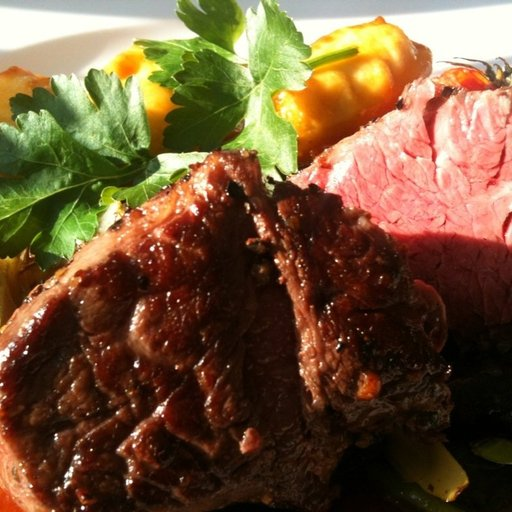

In [9]:

import matplotlib.pyplot as plt
import random
from  PIL import Image

# random.seed(42)

image_path_list = list(image_path.glob("*/*/*.jpg")) # dir->file->content


random_image_path = random.choice(image_path_list)

random_image_path

image_class = random_image_path.parent.stem


img = Image.open(random_image_path)

print(f"random image path:{random_image_path}")
print(f"image class:{image_class}")
print(f"image height:{img.height}")
print(f"image width:{img.width}")
img


(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

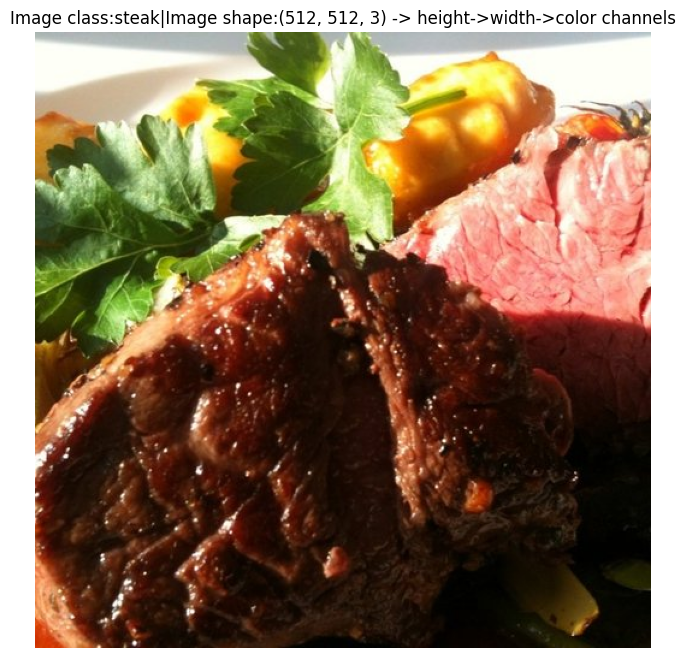

In [10]:
import numpy as np
import matplotlib.pyplot as plt


img_as_array = np.asarray(img)
plt.figure(figsize=(12,8))
plt.imshow(img_as_array)
plt.title(f"Image class:{image_class}|Image shape:{img_as_array.shape} -> height->width->color channels")
plt.axis(False)


### Transforming data into tensors
before using any kind of data turn it into tensors
`Datasets & DataLoaders`

In [11]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms



In [12]:
data_transform = transforms.Compose([
    #resize images
    transforms.Resize(size=(64,64)),
    #Flip the images
    transforms.RandomHorizontalFlip(p=0.5),
    #turning image into torch.tensor
    transforms.ToTensor()
])
data_transform(img).dtype

torch.float32

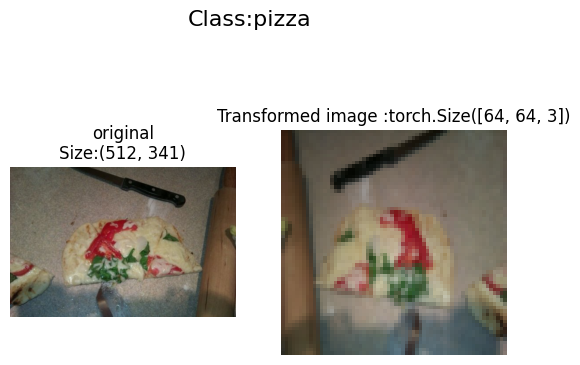

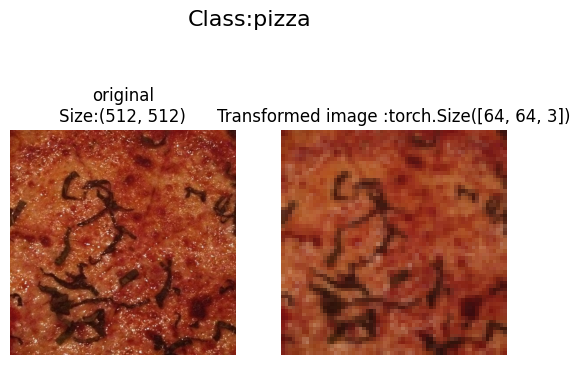

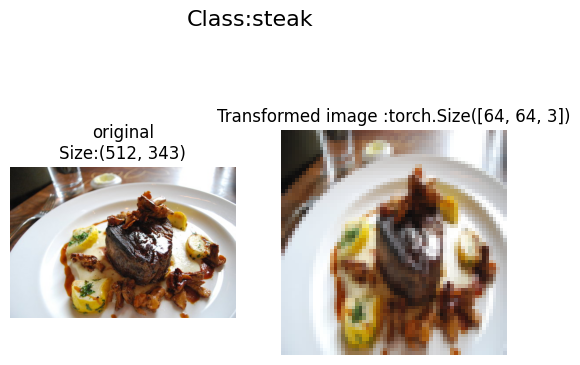

In [13]:
def plot_transformed_images(image_path,
                             transform,
                             n=3,
                             seed=42):
  if seed:
    random.seed(seed)
  random_image_path = random.sample(image_path, k=n)
  for image_path in random_image_path:
    with Image.open(image_path) as f:
      fig, ax = plt.subplots(nrows=1,ncols=2)
      ax[0].imshow(f)
      ax[0].set_title(f"original\nSize:{f.size}")
      ax[0].axis(False)

      transformed_image = transform(f).permute(1,2,0)#color, height,width
      ax[1].imshow(transformed_image)
      ax[1].set_title(f"Transformed image :{transformed_image.shape}")
      ax[1].axis(False)

      fig.suptitle(f"Class:{image_path.parent.stem}", fontsize=16)


plot_transformed_images(image_path=image_path_list,
                        transform=data_transform,
                        n=3,
                        seed=None)


### Loading images data using ImageFolder

In [14]:
from torchvision import datasets

train_data = datasets.ImageFolder(root=train_dir,
                                  transform=data_transform,
                                  target_transform=None)
test_data = datasets.ImageFolder(root=test_dir,
                                 transform=data_transform,
                                 )

train_data, test_data

(Dataset ImageFolder
     Number of datapoints: 225
     Root location: data/pizza_steak_sushi/train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 75
     Root location: data/pizza_steak_sushi/test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ))

In [15]:
class_name = test_data.classes
class_name

['pizza', 'steak', 'sushi']

In [16]:
inx_name = test_data.class_to_idx
inx_name

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [17]:
len(train_data), len(test_data)

(225, 75)

In [18]:
img, label = train_data[0][0],train_data[0][1]
img, label

(tensor([[[0.1176, 0.1216, 0.1255,  ..., 0.0980, 0.1020, 0.1137],
          [0.1294, 0.1294, 0.1294,  ..., 0.0980, 0.0980, 0.1059],
          [0.1333, 0.1333, 0.1333,  ..., 0.0941, 0.0980, 0.1020],
          ...,
          [0.1686, 0.1647, 0.1686,  ..., 0.1255, 0.1098, 0.1098],
          [0.1686, 0.1647, 0.1686,  ..., 0.1098, 0.0941, 0.0902],
          [0.1647, 0.1647, 0.1686,  ..., 0.0980, 0.0863, 0.0863]],
 
         [[0.0588, 0.0588, 0.0588,  ..., 0.0745, 0.0706, 0.0745],
          [0.0627, 0.0627, 0.0627,  ..., 0.0745, 0.0706, 0.0745],
          [0.0706, 0.0706, 0.0706,  ..., 0.0745, 0.0745, 0.0706],
          ...,
          [0.2392, 0.2392, 0.2510,  ..., 0.1373, 0.1333, 0.1255],
          [0.2314, 0.2392, 0.2510,  ..., 0.1255, 0.1176, 0.1098],
          [0.2275, 0.2353, 0.2431,  ..., 0.1137, 0.1059, 0.1020]],
 
         [[0.0196, 0.0196, 0.0157,  ..., 0.0902, 0.0902, 0.0941],
          [0.0196, 0.0157, 0.0196,  ..., 0.0902, 0.0863, 0.0902],
          [0.0196, 0.0157, 0.0157,  ...,

In [19]:
class_name[label]

'pizza'

original shape:torch.Size([3, 64, 64])
after permute:torch.Size([64, 64, 3])


Text(0.5, 1.0, 'pizza')

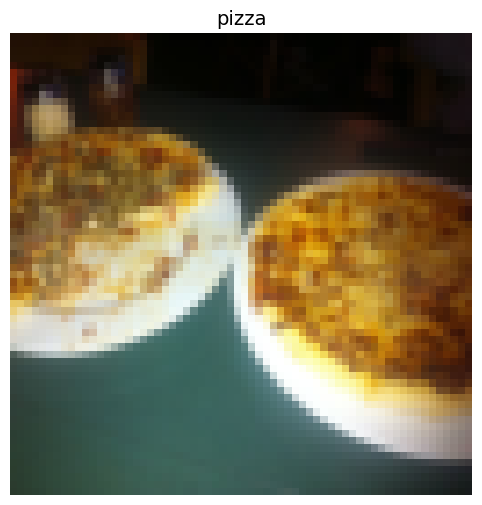

In [20]:
img_permute = img.permute(1,2,0)

print(f"original shape:{img.shape}")
print(f"after permute:{img_permute.shape}")

plt.figure(figsize=(10,6))
plt.imshow(img_permute)
plt.axis(False)
plt.title(class_name[label], fontsize=14)

In [21]:
import os
os.cpu_count()

2

### Turning datasets into dataloader

In [22]:
from torch.utils.data import DataLoader
train_dataloader = DataLoader(dataset=train_data,
                              batch_size=1,
                              num_workers=1,
                              shuffle=True)
test_dataloader = DataLoader(dataset=test_data,
                             batch_size=1,
                             num_workers=1,
                             shuffle=False)

len(train_dataloader), len(test_dataloader)

(225, 75)

In [23]:
img, label = next(iter(train_dataloader))

print(f"image shape : {img.shape}")
print(f"label shape: {label.shape}")

image shape : torch.Size([1, 3, 64, 64])
label shape: torch.Size([1])


### loading iamge data with a custom datasets

In [24]:
import os
import pathlib
import torch


from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms
from typing import Tuple, Dict, List

## creating helper function to get class name

target_directory = train_dir
print(f"target dir {target_directory}")

class_name_found = sorted([entry.name for entry in list(os.scandir(target_directory))])

class_name_found

target dir data/pizza_steak_sushi/train


['pizza', 'steak', 'sushi']

In [25]:
list(os.scandir(target_directory))

[<DirEntry 'sushi'>, <DirEntry 'steak'>, <DirEntry 'pizza'>]

In [26]:
def find_classes(directory:str)-> Tuple[list[str], Dict[str,int]]:
  classes = sorted(entry.name for entry in os.scandir(directory) if entry.is_dir())

  if not classes:
    raise FileNotFoundError(f"couldn't find any classes in{directory}...please check file structure")
  class_to_idx = {class_name: i for i, class_name in enumerate(classes)}
  return classes, class_to_idx

In [27]:
find_classes(target_directory)

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

In [28]:
import torch
from torch.utils.data import Dataset

class ImageFolderCustom(Dataset):
  def __init__(self, tar_dir:str,transform=None):
    self.paths = list(pathlib.Path(tar_dir).glob("*/*.jpg"))
    self.transform = transform
    self.classes, self.class_to_idx = find_classes(tar_dir)


  def  load_Image(self, index:int) -> Image.Image:
    image_path = self.paths[index]
    return Image.open(image_path)

  def __len__(self) -> int:
    return len(self.paths)


  def __getitem__(self, index:int) -> Tuple[torch.Tensor, int]:
    img = self.load_Image(index)
    class_name = self.paths[index].parent.name
    class_to_idx = self.class_to_idx[class_name]

    if self.transform:
      return self.transform(img), class_to_idx
    else:
      return img, class_to_idx

ImageFolderCustom(target_directory)

In [29]:
train_transforms = transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.transforms.ToTensor()
])


In [30]:
train_data_custom = ImageFolderCustom(tar_dir=train_dir,
                                      transform=train_transforms)

test_data_custom = ImageFolderCustom(tar_dir=test_dir,
                                     transform=test_transform)

In [31]:
train_data_custom, test_data_custom

(<__main__.ImageFolderCustom at 0x7f0f09f34cd0>,
 <__main__.ImageFolderCustom at 0x7f0f09f34a50>)

In [32]:
print(len(train_data), len(train_data_custom))
print(len(test_data), len(test_data_custom))
print(train_data_custom.classes == train_data.classes)
print(test_data_custom.classes == test_data.classes)

225 225
75 75
True
True


### Creating custom imagefolder class

In [33]:
def DisplayRandomImages(dataset: torch.utils.data.Dataset,
                        classes:List[str] = True,
                        n:int = 10,
                        display_shape:bool = True,
                        seed: int=None):
  if n > 10:
    n=10
    display_shape = False
    print(f"For display purpose n shouldn't be larger then 10")

  if seed:
    random.seed(seed)


  plt.figure(figsize=(16,8))

  random_samples_idx = random.sample(range(len(dataset)), k=n)

  for i, tar_sample in enumerate(random_samples_idx):
    tar_image, tar_label = dataset[tar_sample][0], dataset[tar_sample][1]

    tar_image_adjust = tar_image.permute(1,2,0)

    plt.subplot(1, n, i+1)
    plt.imshow(tar_image_adjust)
    plt.axis(False)
    if classes:
      title = f"classes:{classes[tar_label]}"
      if display_shape:
        title = title + f"\nshape:{tar_image_adjust.shape}"
      plt.title(title)




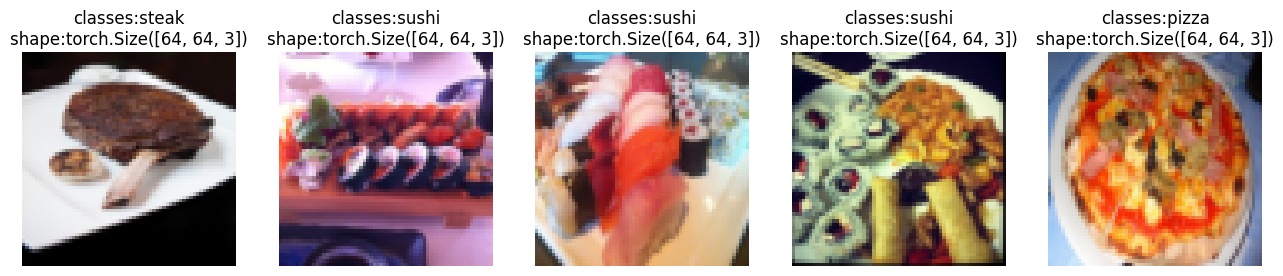

In [34]:
DisplayRandomImages(train_data,
                    n=5,
                    classes=class_name,
                    seed=None)

For display purpose n shouldn't be larger then 10


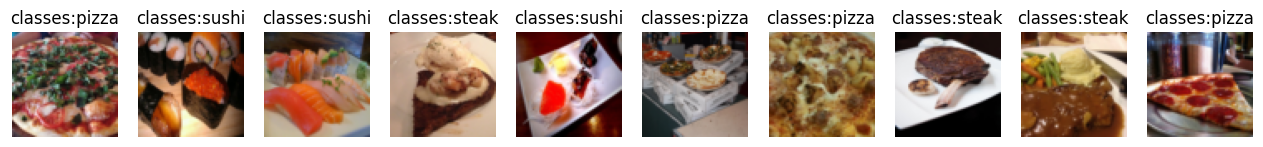

In [35]:
DisplayRandomImages(train_data_custom,
                    n=11,
                    classes=class_name,
                    seed=None)

### Using custom datasets creating dataloaders

In [36]:
from torch.utils.data import DataLoader
train_custom_dataloader = DataLoader(dataset=train_data_custom,
                              batch_size=1,
                              num_workers=0,
                              shuffle=True)
test_custom_dataloader = DataLoader(dataset=test_data_custom,
                             batch_size=1,
                             num_workers=0,
                             shuffle=False)

print(len(train_custom_dataloader), len(test_custom_dataloader))
print(len(train_dataloader), len(test_dataloader))

225 75
225 75


In [37]:
img_custom, label_custom = next(iter(train_custom_dataloader))
img_custom.shape, label_custom.shape

(torch.Size([1, 3, 64, 64]), torch.Size([1]))

###Other forms of data transform DATA AUGMENTATION

DATA AUGUMENTATION: Is the process of artifcially adding diversity to your training data
(we can add various iamges transformatation to the training images )
**Looking at the same image but in different perpective (so that the model can learn different and hard patterns in our data)**

In [38]:
train_transforms = transforms.Compose([
    transforms.Resize(size=(224,224)),
    transforms.TrivialAugmentWide(num_magnitude_bins=31),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize(size=(224,224)),
    transforms.ToTensor()
])



In [39]:
image_path

PosixPath('data/pizza_steak_sushi')

In [40]:
image_path_list = list(image_path.glob("*/*/*.jpg"))
image_path_list[:10]

[PosixPath('data/pizza_steak_sushi/train/sushi/929471.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/377047.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/1070104.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/424994.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/2574453.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/1138695.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/3426958.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/1551817.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/2019344.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/121940.jpg')]

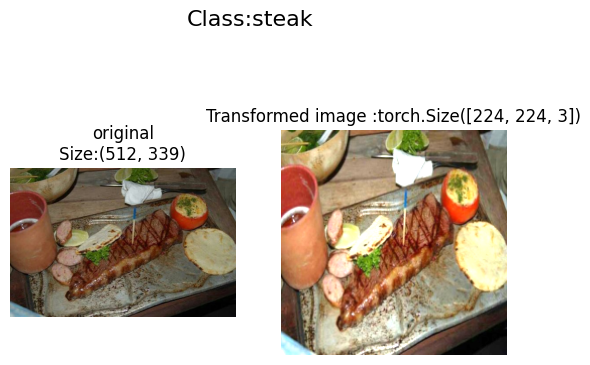

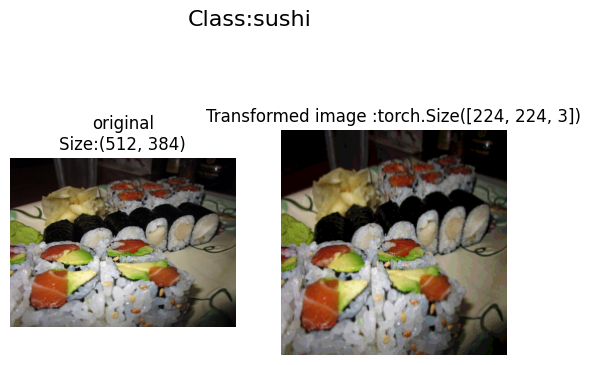

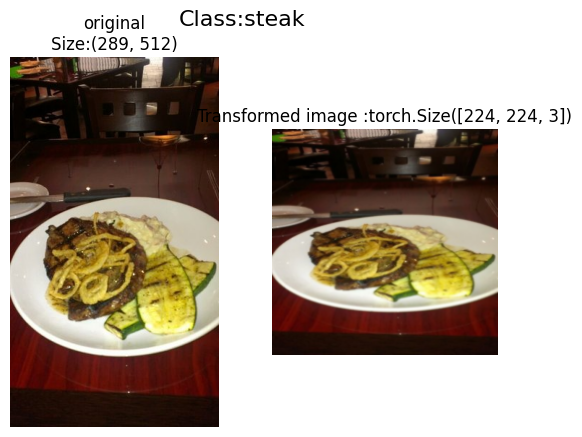

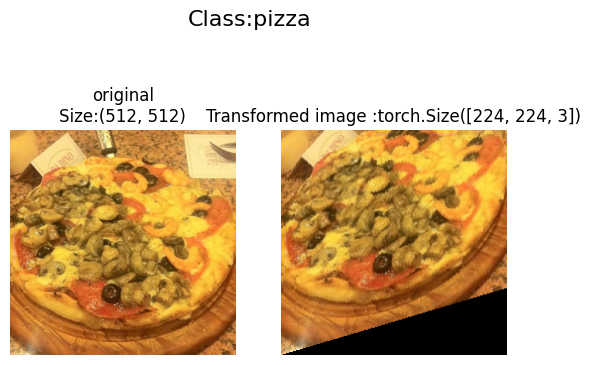

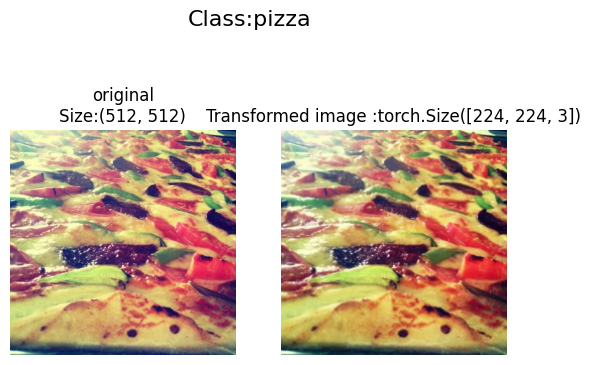

In [41]:
plot_transformed_images(
    image_path=image_path_list,
    transform=train_transforms,
    n=5,
    seed=None
)

###Model0 : without data agumentation

In [42]:
simple_transforms = transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.ToTensor()
])

In [74]:
from torchvision import datasets
train_data_simple = datasets.ImageFolder(root=train_dir,
                                         transform=simple_transforms)
test_data_simple = datasets.ImageFolder(root=test_dir,
                                        transform=simple_transforms)

import os
from torch.utils.data import DataLoader

BATCH_SIZE = 32
NUM_WORKERS = os.cpu_count()

train_dataloader_simple = DataLoader(dataset=train_data_simple,
                                     batch_size=BATCH_SIZE,
                                     num_workers=NUM_WORKERS,
                                     shuffle=True)
test_dataloader_simple = DataLoader(dataset=test_data_simple,
                                    batch_size=BATCH_SIZE,
                                    shuffle=False,
                                    num_workers=NUM_WORKERS)






### Creating tiny VGGG

In [75]:
from numpy.lib import stride_tricks
class TinyVGG(nn.Module):
  def __init__(self,
               input_shape:int,
               hidden_units:int,
               output_shape:int) -> None:
    super().__init__()
    self.conv_block_1 = nn.Sequential(
        nn.Conv2d(in_channels=input_shape,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,
                     stride=2)
    )
    self.conv_block_2 = nn.Sequential(
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,
                     stride=2)
    )
    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=hidden_units * 16 * 16,
                  out_features=output_shape)
    )

  def forward(self,x):
    # x = self.conv_block_1(x)
    # # print(x.shape)
    # x = self.conv_block_2(x)
    # # print(x.shape)
    # return x
    return self.classifier(self.conv_block_2(self.conv_block_1(x)))


In [76]:
torch.manual_seed(42)
model_0 = TinyVGG(input_shape=3,
       hidden_units=13,
        output_shape=len(class_name))
model_0

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 13, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(13, 13, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(13, 13, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(13, 13, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3328, out_features=3, bias=True)
  )
)

### Trying and pssing a dummy data to test our mdoel

In [77]:
image_batch, lebel_batch = next(iter(train_dataloader_simple))

image_batch.shape, lebel_batch.shape

(torch.Size([32, 3, 64, 64]), torch.Size([32]))

In [78]:
model_0(image_batch)

tensor([[-0.0184,  0.0289, -0.0083],
        [-0.0179,  0.0305, -0.0078],
        [-0.0190,  0.0288, -0.0071],
        [-0.0226,  0.0297, -0.0078],
        [-0.0223,  0.0301, -0.0080],
        [-0.0201,  0.0288, -0.0038],
        [-0.0199,  0.0299, -0.0093],
        [-0.0196,  0.0275, -0.0067],
        [-0.0179,  0.0281, -0.0066],
        [-0.0182,  0.0271, -0.0078],
        [-0.0222,  0.0321, -0.0102],
        [-0.0187,  0.0302, -0.0082],
        [-0.0169,  0.0298, -0.0055],
        [-0.0203,  0.0314, -0.0085],
        [-0.0173,  0.0275, -0.0056],
        [-0.0189,  0.0303, -0.0072],
        [-0.0171,  0.0285, -0.0078],
        [-0.0172,  0.0289, -0.0057],
        [-0.0203,  0.0275, -0.0066],
        [-0.0229,  0.0308, -0.0108],
        [-0.0228,  0.0362, -0.0125],
        [-0.0200,  0.0296, -0.0068],
        [-0.0226,  0.0348, -0.0088],
        [-0.0157,  0.0283, -0.0080],
        [-0.0174,  0.0327, -0.0079],
        [-0.0220,  0.0283, -0.0092],
        [-0.0196,  0.0307, -0.0067],
 

In [79]:
pip install torchinfo

In [80]:
import torchinfo
from torchinfo import summary

summary(model_0, input_size=[1,3,64,64])

Layer (type:depth-idx)                   Output Shape              Param #
TinyVGG                                  [1, 3]                    --
├─Sequential: 1-1                        [1, 13, 32, 32]           --
│    └─Conv2d: 2-1                       [1, 13, 64, 64]           364
│    └─ReLU: 2-2                         [1, 13, 64, 64]           --
│    └─Conv2d: 2-3                       [1, 13, 64, 64]           1,534
│    └─ReLU: 2-4                         [1, 13, 64, 64]           --
│    └─MaxPool2d: 2-5                    [1, 13, 32, 32]           --
├─Sequential: 1-2                        [1, 13, 16, 16]           --
│    └─Conv2d: 2-6                       [1, 13, 32, 32]           1,534
│    └─ReLU: 2-7                         [1, 13, 32, 32]           --
│    └─Conv2d: 2-8                       [1, 13, 32, 32]           1,534
│    └─ReLU: 2-9                         [1, 13, 32, 32]           --
│    └─MaxPool2d: 2-10                   [1, 13, 16, 16]           --
├─Seq

### Creating test and train loops functions

In [81]:
loss = nn.L1Loss()

optimizer = torch.optim.SGD(params=model_0.parameters(),
                            lr=0.1)

In [82]:
def train_step(model:torch.nn.Module,
               dataloader:torch.utils.data.DataLoader,
               loss_fn :torch.nn.Module,
               optimizer:torch.optim.Optimizer,
               device=device):
  model.train()

  train_loss, train_acc = 0,0

  for batch, (x,y) in enumerate(dataloader):
    x,y = x, y

    y_pred = model(x)

    loss = loss_fn(y_pred, y)
    train_loss += loss.item()

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    y_pred_class= torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
    train_acc += (y_pred_class==y).sum().item()/len(y_pred)


  train_loss = train_loss / len(dataloader)
  train_acc = train_acc / len(dataloader)

  return train_loss, train_acc


In [83]:
## test steps
def test_step(model: torch.nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: nn.Module,
              device=device):
  model.eval()
  test_loss, test_acc = 0, 0
  with torch.inference_mode():
    for batch, (x, y) in enumerate(dataloader):
      x, y = x, y
      test_pred_logits = model(x)
      loss = loss_fn(test_pred_logits, y)
      test_loss += loss.item()
      test_pred_labels = test_pred_logits.argmax(dim=1)
      test_acc += ((test_pred_labels == y).sum().item() / len(test_pred_labels))


  test_loss = test_loss / len(dataloader)
  test_acc = test_acc / len(dataloader)
  return test_loss, test_acc

### Creating train function

In [84]:
from tqdm.auto import tqdm

def train(model:torch.nn.Module,
          train_dataloader:torch.utils.data.DataLoader,
          test_dataloader:torch.utils.data.DataLoader,
          optimizer: torch.optim.Optimizer,
          epochs:int=5,
          loss_fn:torch.nn.Module = nn.CrossEntropyLoss(),
          device=device):
  results = {"train_loss":[],
             "train_acc":[],
             "test_loss":[],
             "test_acc":[]}
  for epoch in tqdm(range(epochs)):
    train_loss, train_acc = train_step(model=model,
                                       dataloader=train_dataloader,
                                       loss_fn=loss_fn,
                                       optimizer=optimizer,
                                       device=device)
    test_loss, test_acc = test_step(model=model,
                                      dataloader=test_dataloader,
                                      loss_fn=loss_fn,
                                      device=device)

    print(f"Epoch:{epoch}|Train loss:{train_loss:.4f} |Train acc:{train_acc:.2f}% | Test loss:{test_loss:.4f}| Test acc:{test_acc:.2f}%")


    results["train_loss"].append(train_loss)
    results["train_acc"].append(train_acc)
    results["test_loss"].append(test_loss)
    results["test_acc"].append(test_acc)


  return results





In [85]:
torch.manual_seed(42)

NUM_EPOCHS = 30

model_0 = TinyVGG(input_shape=3,
                  hidden_units=10,
                  output_shape=len(train_data.classes))

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(params=model_0.parameters(),
                             lr=0.001)

from timeit import default_timer as timer
start_time = timer()

model_0_results = train(model=model_0,
                        train_dataloader=train_dataloader_simple,
                        test_dataloader=test_dataloader_simple,
                        optimizer=optimizer,
                        epochs=NUM_EPOCHS,
                        loss_fn=loss_fn,
                        device=device)
end_time = timer()

print(f"Total trainig time :{end_time-start_time:.3f} seconds")

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch:0|Train loss:1.1078 |Train acc:0.26% | Test loss:1.1362| Test acc:0.26%
Epoch:1|Train loss:1.0846 |Train acc:0.43% | Test loss:1.1622| Test acc:0.20%
Epoch:2|Train loss:1.1153 |Train acc:0.29% | Test loss:1.1695| Test acc:0.20%
Epoch:3|Train loss:1.0989 |Train acc:0.41% | Test loss:1.1343| Test acc:0.20%
Epoch:4|Train loss:1.0989 |Train acc:0.29% | Test loss:1.1434| Test acc:0.20%
Epoch:5|Train loss:1.0962 |Train acc:0.30% | Test loss:1.1484| Test acc:0.26%
Epoch:6|Train loss:1.1183 |Train acc:0.32% | Test loss:1.1414| Test acc:0.33%
Epoch:7|Train loss:1.1013 |Train acc:0.36% | Test loss:1.1045| Test acc:0.21%
Epoch:8|Train loss:1.0887 |Train acc:0.49% | Test loss:1.0669| Test acc:0.54%
Epoch:9|Train loss:1.0670 |Train acc:0.40% | Test loss:1.0157| Test acc:0.54%
Epoch:10|Train loss:1.0444 |Train acc:0.42% | Test loss:0.9765| Test acc:0.60%
Epoch:11|Train loss:1.1370 |Train acc:0.40% | Test loss:1.0052| Test acc:0.37%
Epoch:12|Train loss:1.0312 |Train acc:0.46% | Test loss:1.0059

In [86]:
model_0_results

{'train_loss': [1.1078356504440308,
  1.084644876420498,
  1.1152998358011246,
  1.098892256617546,
  1.0989442765712738,
  1.096214696764946,
  1.1182934939861298,
  1.1012653410434723,
  1.0887064188718796,
  1.0669903978705406,
  1.0443589463829994,
  1.1369613409042358,
  1.0311735421419144,
  0.971842959523201,
  0.9066804647445679,
  0.8021928556263447,
  0.808090053498745,
  0.8375555351376534,
  0.844354897737503,
  1.0630183666944504,
  0.8517085611820221,
  0.8554658517241478,
  0.8417275324463844,
  0.7302049975842237,
  0.9418155029416084,
  0.7806155756115913,
  0.8176937103271484,
  0.6838352233171463,
  0.6827480653300881,
  0.9686764106154442],
 'train_acc': [0.2578125,
  0.42578125,
  0.29296875,
  0.4140625,
  0.29296875,
  0.296875,
  0.31640625,
  0.35546875,
  0.48828125,
  0.40234375,
  0.421875,
  0.40234375,
  0.45703125,
  0.49609375,
  0.57421875,
  0.66015625,
  0.6953125,
  0.6953125,
  0.58203125,
  0.55859375,
  0.6484375,
  0.625,
  0.61328125,
  0.667968

In [87]:
## Plottig loss curves of model_0 - (tracking model progress over time)
## we have underfitting - overfitting - just right
## We aim for just right loss curves
model_0_results.keys()

dict_keys(['train_loss', 'train_acc', 'test_loss', 'test_acc'])

In [88]:

def plot_loss_curves(results: Dict[str, List[float]]):
  loss = results["train_loss"]
  test_loss = results["test_loss"]

  # Change "accuracy" and "test_accuracy" to match your dictionary keys
  accuracy = results["train_acc"]
  test_accuracy = results["test_acc"]

  epochs = range(len(results["train_loss"]))

  plt.figure(figsize=(15, 7))

  # Plot loss
  plt.subplot(1, 2, 1)
  plt.plot(epochs, loss, label="train_loss")
  plt.plot(epochs, test_loss, label="test_loss")
  plt.title("Loss")
  plt.xlabel("Epochs")
  plt.legend()

  # Plot accuracy
  plt.subplot(1, 2, 2)
  plt.plot(epochs, accuracy, label="train_accuracy")
  plt.plot(epochs, test_accuracy, label="test_accuracy")
  plt.title("Accuracy")
  plt.xlabel("Epochs")
  plt.legend()

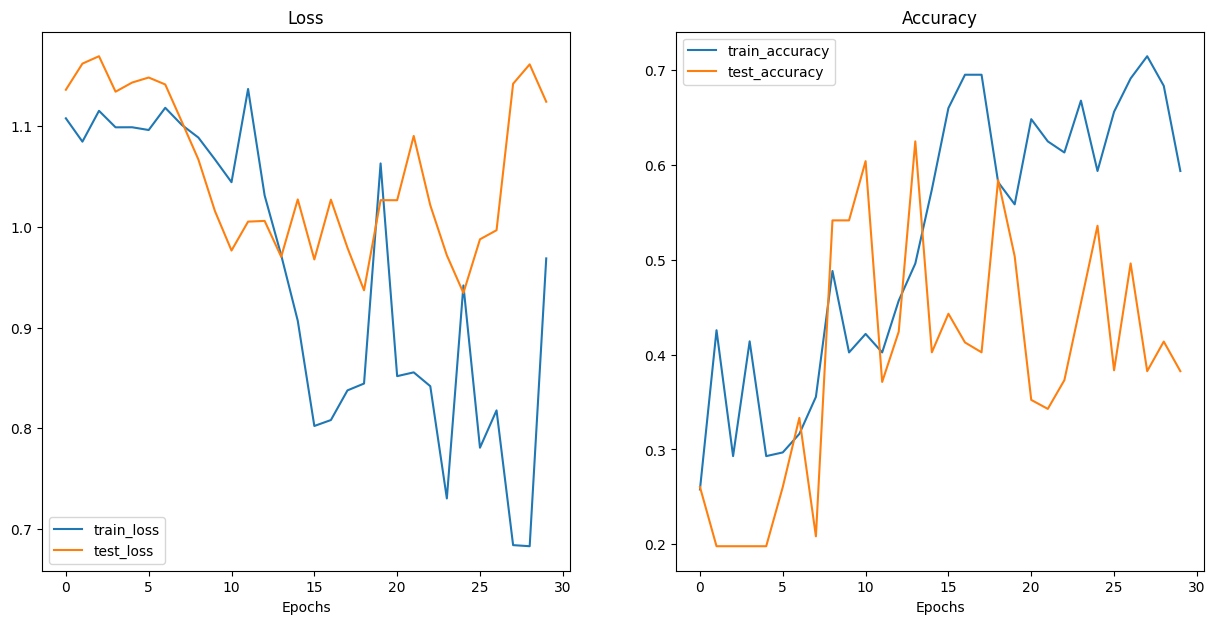

In [89]:
plot_loss_curves(model_0_results)

### TinyVGG with data agumentation

In [90]:
train_transform_trivial = transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.TrivialAugmentWide(num_magnitude_bins=31),
    transforms.ToTensor()
])
test_transform_trivial = transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.ToTensor()
])

In [91]:
## Creating datasets and dataloader

train_data_augmented = datasets.ImageFolder(root=train_dir,
                                            transform=train_transform_trivial)
test_data_simple = datasets.ImageFolder(root=test_dir,
                                        transform=test_transform_trivial)

In [92]:
## Data loader
import os
BATCH_SIZE = 16
NUM_WORKERS = os.cpu_count()

train_dataloader_augmented = DataLoader(dataset=train_data_augmented,
                                        batch_size=BATCH_SIZE,
                                        shuffle=True,
                                        num_workers=NUM_WORKERS)

test_dataloader_simple = DataLoader(dataset=test_data_simple,
                                       batch_size=BATCH_SIZE,
                                       shuffle=False,
                                       num_workers=NUM_WORKERS)


len(train_dataloader_augmented), len(test_dataloader_simple)

(15, 5)

In [93]:
model_1 = TinyVGG(input_shape=3,
                  hidden_units=10,
                  output_shape=len(train_data_augmented.classes))

model_1

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=3, bias=True)
  )
)

In [94]:
torch.manual_seed(42)

NUM_EPOCHS = 15

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(model_1.parameters(),
                             lr=0.001)

start_time = timer()

model_1_results = train(model=model_1,
                        train_dataloader=train_dataloader_augmented,
                        test_dataloader=test_dataloader_simple,
                        optimizer=optimizer,
                        epochs=NUM_EPOCHS,
                        loss_fn=loss_fn,
                        device=device)
end_time = timer()
print(f"total time of training for model_1 = {end_time - start_time:.3f}seconds")




  0%|          | 0/15 [00:00<?, ?it/s]

Epoch:0|Train loss:1.1125 |Train acc:0.27% | Test loss:1.1231| Test acc:0.31%
Epoch:1|Train loss:1.1002 |Train acc:0.39% | Test loss:1.1033| Test acc:0.31%
Epoch:2|Train loss:1.0966 |Train acc:0.39% | Test loss:1.1055| Test acc:0.31%
Epoch:3|Train loss:1.0817 |Train acc:0.45% | Test loss:1.0914| Test acc:0.35%
Epoch:4|Train loss:1.0399 |Train acc:0.53% | Test loss:1.0245| Test acc:0.44%
Epoch:5|Train loss:0.9884 |Train acc:0.55% | Test loss:1.1053| Test acc:0.45%
Epoch:6|Train loss:0.9920 |Train acc:0.51% | Test loss:1.0496| Test acc:0.37%
Epoch:7|Train loss:0.9964 |Train acc:0.47% | Test loss:1.0112| Test acc:0.41%
Epoch:8|Train loss:0.9602 |Train acc:0.57% | Test loss:1.0302| Test acc:0.44%
Epoch:9|Train loss:0.9495 |Train acc:0.57% | Test loss:1.0040| Test acc:0.43%
Epoch:10|Train loss:0.9454 |Train acc:0.58% | Test loss:1.0596| Test acc:0.40%
Epoch:11|Train loss:0.8745 |Train acc:0.58% | Test loss:1.0250| Test acc:0.42%
Epoch:12|Train loss:0.8781 |Train acc:0.61% | Test loss:1.1222

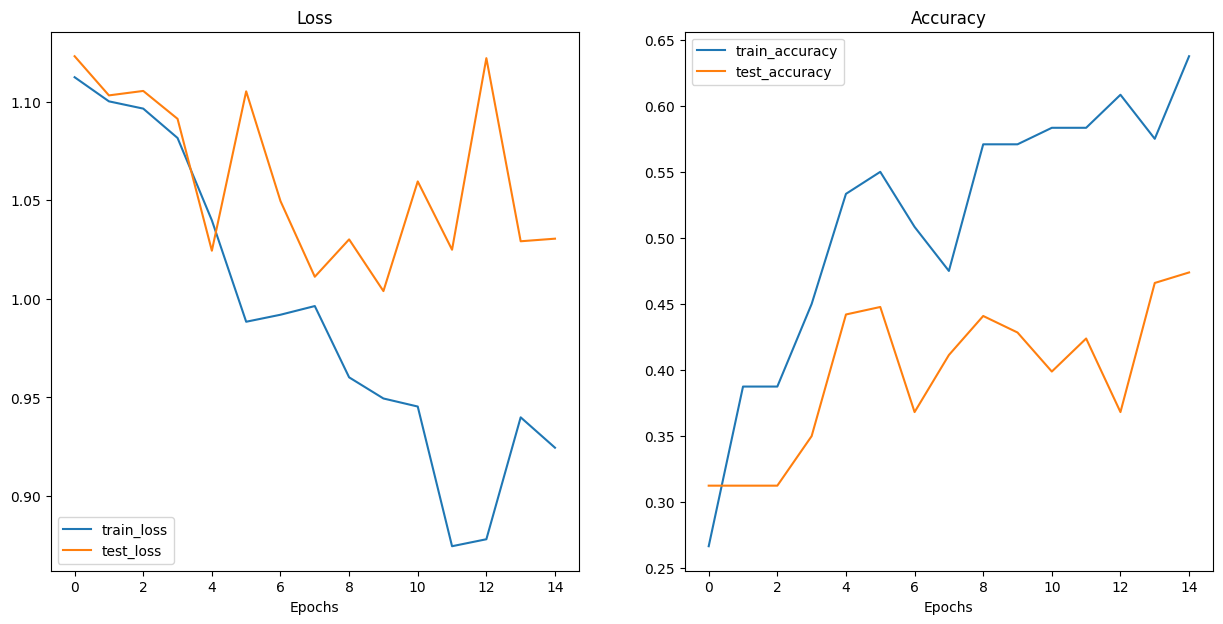

In [95]:
plot_loss_curves(results=model_1_results)

In [103]:
model_0_df = pd.DataFrame(model_0_results)
model_1_df = pd.DataFrame(model_1_results)

model_1_df

,train_loss,train_acc,test_loss,test_acc
0,1.112483,0.266667,1.123135,0.312500
1,1.100239,0.387500,1.103261,0.312500
2,1.096554,0.387500,1.105522,0.312500
3,1.081651,0.450000,1.091374,0.350000
4,1.039879,0.533333,1.024456,0.442045
5,0.988416,0.550000,1.105311,0.447727
6,0.991975,0.508333,1.049639,0.368182
7,0.996380,0.475000,1.011245,0.411364
8,0.960212,0.570833,1.030204,0.440909
9,0.949486,0.570833,1.003965,0.428409


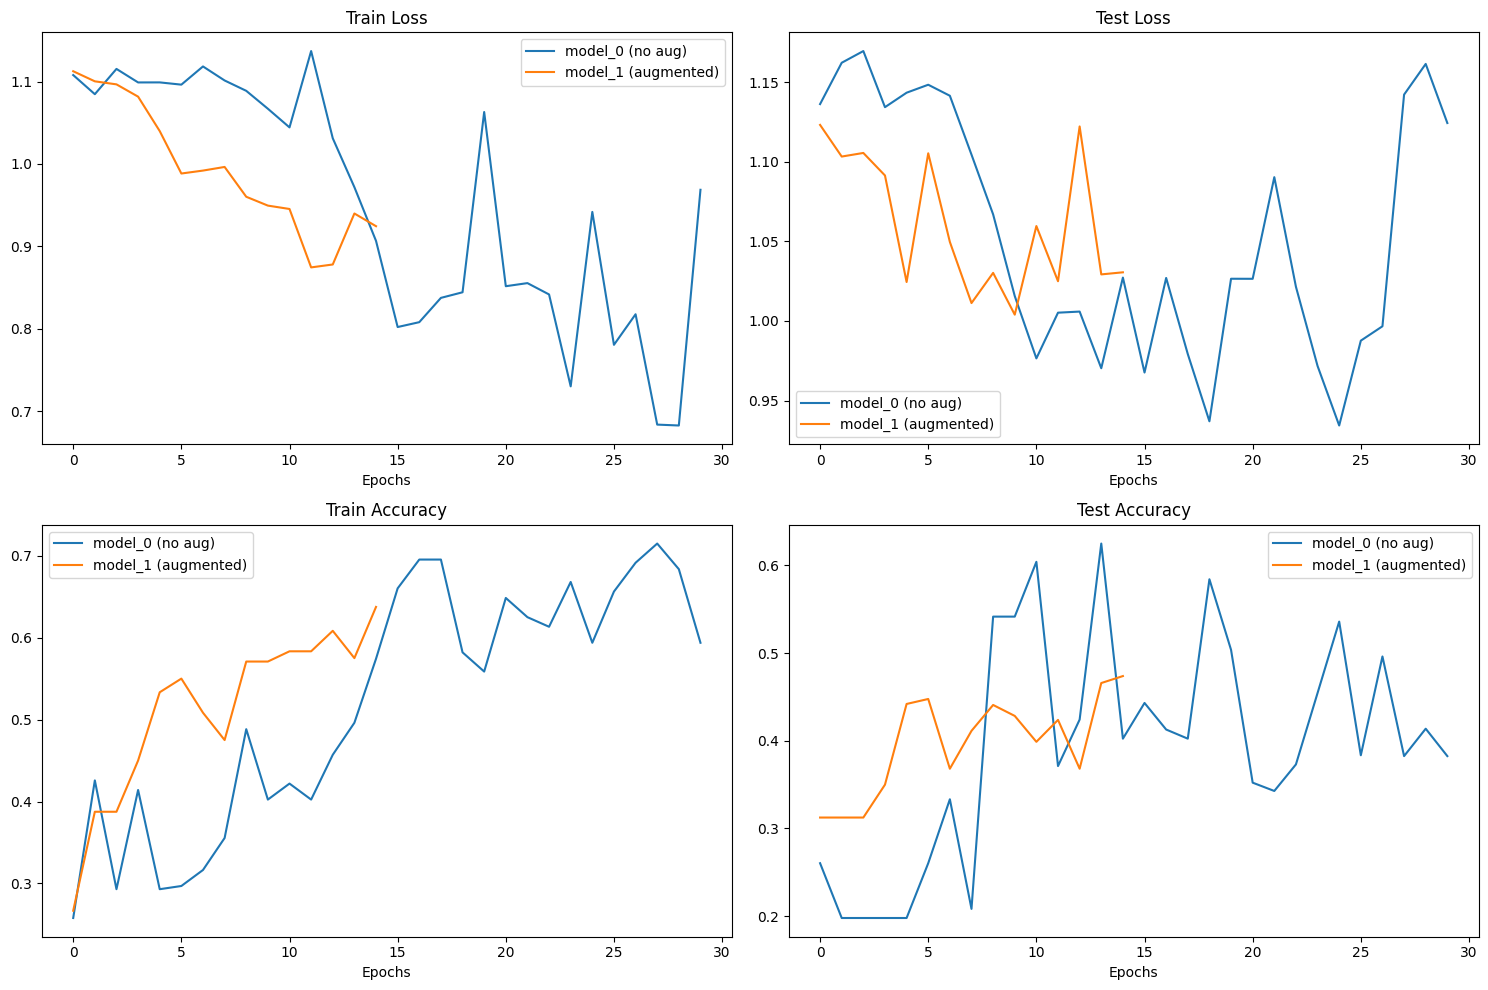

In [98]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Convert both result dicts into DataFrames
model_0_df = pd.DataFrame(model_0_results)
model_1_df = pd.DataFrame(model_1_results)

# 2. Plot side-by-side comparison curves
plt.figure(figsize=(15, 10))

# Get epoch ranges (model_0 has 30 epochs, model_1 has 15 epochs)
epochs_0 = range(len(model_0_df))
epochs_1 = range(len(model_1_df))

# Plot Train Loss
plt.subplot(2, 2, 1)
plt.plot(epochs_0, model_0_df["train_loss"], label="model_0 (no aug)")
plt.plot(epochs_1, model_1_df["train_loss"], label="model_1 (augmented)")
plt.title("Train Loss")
plt.xlabel("Epochs")
plt.legend()

# Plot Test Loss
plt.subplot(2, 2, 2)
plt.plot(epochs_0, model_0_df["test_loss"], label="model_0 (no aug)")
plt.plot(epochs_1, model_1_df["test_loss"], label="model_1 (augmented)")
plt.title("Test Loss")
plt.xlabel("Epochs")
plt.legend()

# Plot Train Accuracy
plt.subplot(2, 2, 3)
plt.plot(epochs_0, model_0_df["train_acc"], label="model_0 (no aug)")
plt.plot(epochs_1, model_1_df["train_acc"], label="model_1 (augmented)")
plt.title("Train Accuracy")
plt.xlabel("Epochs")
plt.legend()

# Plot Test Accuracy
plt.subplot(2, 2, 4)
plt.plot(epochs_0, model_0_df["test_acc"], label="model_0 (no aug)")
plt.plot(epochs_1, model_1_df["test_acc"], label="model_1 (augmented)")
plt.title("Test Accuracy")
plt.xlabel("Epochs")
plt.legend()

plt.tight_layout()
plt.show()